# Nassau Candy - Profitability Analysis

One notebook for cleaning, analysis, machine learning and saving outputs.
Run it from the project folder. Put the CSV in `data/raw/`.

## 1. Setup

In [25]:
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid")

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../output/figures")
MODELS = Path("../models")

for folder in [PROCESSED, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight")

## 2. Load data

In [26]:
data = pd.read_csv(RAW / "Nassau_Candy_Distributor.csv")

print("Rows and columns:", data.shape)
display(data.head())

Rows and columns: (10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


## 3. Explore data

In [27]:
data.info()
display(data.isna().sum())
display(data.describe().T)

print("Duplicate rows:", data.duplicated().sum())
print("Products:", data["Product Name"].nunique())
print("Divisions:", data["Division"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
Row ID,10194.0,5097.500000,2942.898656,1.00,2549.25,5097.50,7645.75,10194.0
Customer ID,10194.0,134468.961154,20231.483007,100006.00,117212.00,133550.00,152051.00,192314.0
Sales,10194.0,13.908537,11.341020,1.25,7.20,10.80,18.00,260.0
Units,10194.0,3.791838,2.228317,1.00,2.00,3.00,5.00,14.0
Gross Profit,10194.0,9.166451,6.643740,0.25,4.90,7.47,12.25,130.0
Cost,10194.0,4.742087,5.061647,0.60,2.40,3.60,5.70,130.0


Duplicate rows: 0
Products: 15
Divisions: <ArrowStringArray>
['Chocolate', 'Other', 'Sugar']
Length: 3, dtype: str


## 4. Check the Ship Date column

In [28]:
# Dates in this file are written day-month-year, for example 03-01-2024
order_date = pd.to_datetime(data["Order Date"], format="%d-%m-%Y")
ship_date = pd.to_datetime(data["Ship Date"], format="%d-%m-%Y")
shipping_days = (ship_date - order_date).dt.days

print("Order dates:", order_date.min().date(), "to", order_date.max().date())
print("Ship dates:", ship_date.min().date(), "to", ship_date.max().date())
display(shipping_days.describe())

print("Shipping takes at least", shipping_days.min(), "days, which is not real.")
print("So Ship Date is not used in this project.")

Order dates: 2024-01-02 to 2025-12-31
Ship dates: 2026-06-30 to 2030-06-28


count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

Shipping takes at least 904 days, which is not real.
So Ship Date is not used in this project.


## 5. Clean data

In [29]:
rows_before = len(data)

data = data.drop_duplicates().copy()

# format="%d-%m-%Y" reads the date as day-month-year.
# Without it, pandas reads the day as the month and many dates fail.
data["Order Date"] = pd.to_datetime(data["Order Date"], format="%d-%m-%Y", errors="coerce")

for col in ["Sales", "Units", "Cost", "Gross Profit"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=["Order Date", "Sales", "Units", "Cost"])
data = data[(data["Sales"] > 0) & (data["Units"] > 0) & (data["Cost"] >= 0)]

for col in ["Division", "Product Name", "Ship Mode", "Region", "Country/Region"]:
    data[col] = data[col].fillna("Unknown").astype(str).str.strip()

# Gross Profit = Sales - Cost
difference = data["Gross Profit"] - (data["Sales"] - data["Cost"])
print("Rows with a gross profit difference:", (difference.abs() > 0.01).sum())
data["Gross Profit"] = data["Sales"] - data["Cost"]

# Ship Date is not reliable, so we remove it
data = data.drop(columns=["Ship Date"])

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(data))
print("Rows lost:", rows_before - len(data))
display(data.head())

Rows with a gross profit difference: 0
Rows before cleaning: 10194
Rows after cleaning: 10194
Rows lost: 0


,Row ID,Order ID,Order Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


## 6. Create new columns and save cleaned data

In [30]:
data["Gross Margin"] = data["Gross Profit"] / data["Sales"] * 100
data["Profit Per Unit"] = data["Gross Profit"] / data["Units"]
data["Unit Price"] = (data["Sales"] / data["Units"]).round(2)
data["Unit Cost"] = (data["Cost"] / data["Units"]).round(2)
data["Order Year"] = data["Order Date"].dt.year
data["Order Month"] = data["Order Date"].dt.month
data["Day Of Week"] = data["Order Date"].dt.dayofweek

data.to_csv(PROCESSED / "cleaned_data.csv", index=False)

print("Order dates:", data["Order Date"].min().date(), "to", data["Order Date"].max().date())
print("Negative profit rows:", (data["Gross Profit"] < 0).sum())
print("Cleaned data saved.")

Order dates: 2024-01-02 to 2025-12-31
Negative profit rows: 0
Cleaned data saved.


## 7. Does price or cost change for a product?

In [31]:
price_check = data.groupby("Product Name").agg(
    Different_Prices=("Unit Price", "nunique"),
    Different_Costs=("Unit Cost", "nunique")
)
display(price_check)

# If every product shows 1 and 1, each product has one price and one cost.
# That means the margin of a product never changes.
print("Max different prices for one product:", price_check["Different_Prices"].max())
print("Max different costs for one product:", price_check["Different_Costs"].max())

,Different_Prices,Different_Costs
Product Name,,
Everlasting Gobstopper,1,1
Fizzy Lifting Drinks,1,1
Fun Dip,1,1
Hair Toffee,1,1
Kazookles,1,1
Laffy Taffy,1,1
Lickable Wallpaper,1,1
Nerds,1,1
SweeTARTS,1,1


Max different prices for one product: 1
Max different costs for one product: 1


## 8. Overall KPIs

In [32]:
total_sales = data["Sales"].sum()
total_cost = data["Cost"].sum()
total_profit = data["Gross Profit"].sum()
total_units = data["Units"].sum()
gross_margin = total_profit / total_sales * 100

print(f"Total sales: {total_sales:,.2f}")
print(f"Total cost: {total_cost:,.2f}")
print(f"Gross profit: {total_profit:,.2f}")
print(f"Total units: {total_units:,.0f}")
print(f"Gross margin: {gross_margin:.2f}%")

Total sales: 141,783.63
Total cost: 48,340.83
Gross profit: 93,442.80
Total units: 38,654
Gross margin: 65.91%


## 9. Product analysis

In [33]:
product_summary = data.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Cost=("Cost", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Units=("Units", "sum")
).reset_index()

product_summary["Gross Margin"] = product_summary["Gross_Profit"] / product_summary["Sales"] * 100
product_summary["Profit Per Unit"] = product_summary["Gross_Profit"] / product_summary["Units"]
product_summary["Revenue Contribution"] = product_summary["Sales"] / product_summary["Sales"].sum() * 100
product_summary["Profit Contribution"] = product_summary["Gross_Profit"] / product_summary["Gross_Profit"].sum() * 100

product_summary = product_summary.sort_values("Gross_Profit", ascending=False)
display(product_summary)

product_summary.to_csv(PROCESSED / "product_summary.csv", index=False)

,Product Name,Sales,Cost,Gross_Profit,Units,Gross Margin,Profit Per Unit,Revenue Contribution,Profit Contribution
13,Wonka Bar -Scrumdiddlyumptious,27874.80,8517.30,19357.50,7743,69.444444,2.50,19.660098,20.715882
12,Wonka Bar - Triple Dazzle Caramel,28485.00,9874.80,18610.20,7596,65.333333,2.45,20.090472,19.916141
10,Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,8267,64.923077,2.11,18.949825,18.667431
11,Wonka Bar - Nutty Crunch Surprise,23574.95,6755.00,16819.95,6755,71.346705,2.49,16.627413,18.000263
9,Wonka Bar - Fudge Mallows,24890.40,8296.80,16593.60,6914,66.666667,2.40,17.555200,17.758030
6,Lickable Wallpaper,7860.00,3930.00,3930.00,393,50.000000,10.00,5.543658,4.205782
14,Wonka Gum,597.50,286.80,310.70,478,52.000000,0.65,0.421417,0.332503
0,Everlasting Gobstopper,130.00,26.00,104.00,13,80.000000,8.00,0.091689,0.111298
4,Kazookles,1205.75,1113.00,92.75,371,7.692308,0.25,0.850416,0.099259
3,Hair Toffee,76.50,17.00,59.50,17,77.777778,3.50,0.053955,0.063675


## 10. Product charts

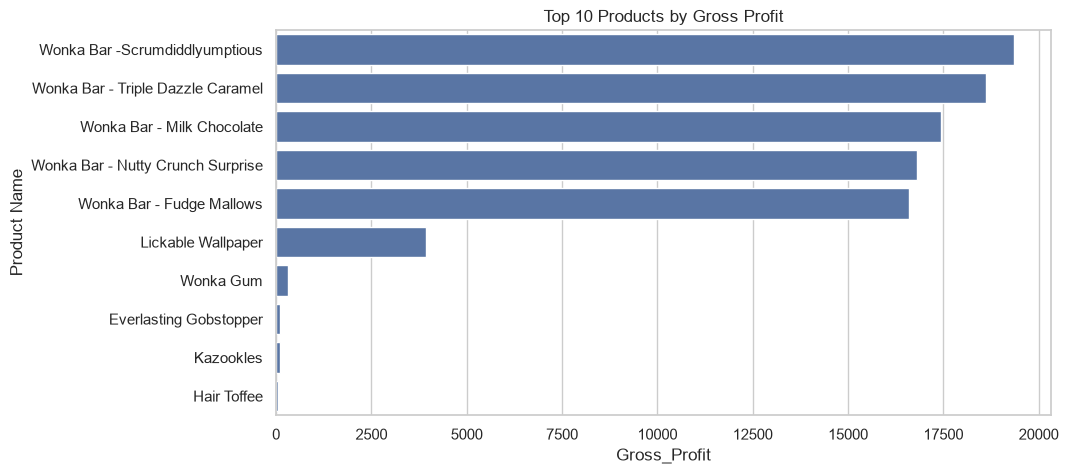

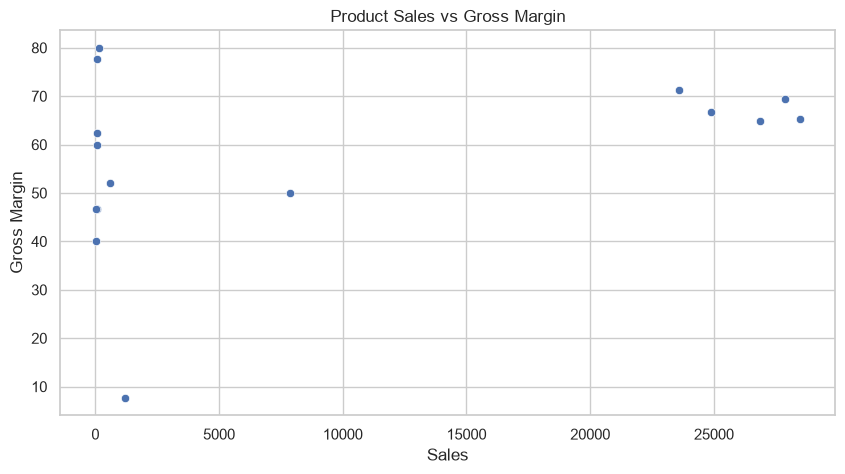

In [34]:
plt.figure(figsize=(10, 5))
sns.barplot(data=product_summary.head(10), x="Gross_Profit", y="Product Name")
plt.title("Top 10 Products by Gross Profit")
save_figure("top_products_profit.png")
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=product_summary, x="Sales", y="Gross Margin")
plt.title("Product Sales vs Gross Margin")
save_figure("product_sales_vs_margin.png")
plt.show()

## 11. Division analysis

,Division,Sales,Cost,Gross_Profit,Units,Gross Margin,Revenue Contribution,Profit Contribution
0,Chocolate,131692.90,42868.28,88824.62,37275,67.448298,92.883008,95.057747
1,Other,9663.25,5329.80,4333.45,1242,44.844643,6.815491,4.637543
2,Sugar,427.48,142.75,284.73,137,66.606625,0.301502,0.304710


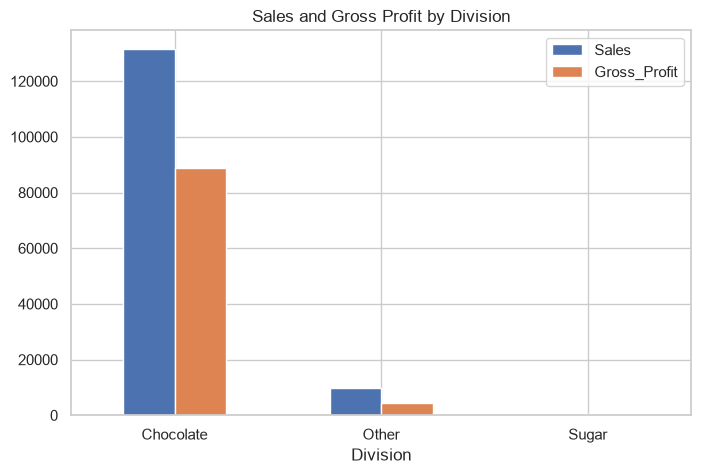

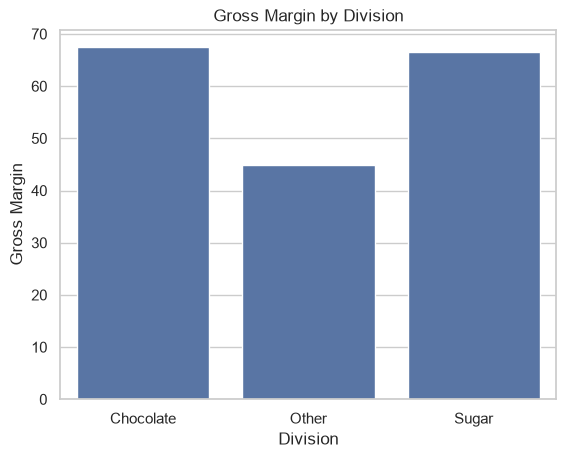

In [35]:
division_summary = data.groupby("Division").agg(
    Sales=("Sales", "sum"),
    Cost=("Cost", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Units=("Units", "sum")
).reset_index()

division_summary["Gross Margin"] = division_summary["Gross_Profit"] / division_summary["Sales"] * 100
division_summary["Revenue Contribution"] = division_summary["Sales"] / division_summary["Sales"].sum() * 100
division_summary["Profit Contribution"] = division_summary["Gross_Profit"] / division_summary["Gross_Profit"].sum() * 100

display(division_summary)
division_summary.to_csv(PROCESSED / "division_summary.csv", index=False)

division_summary.plot(x="Division", y=["Sales", "Gross_Profit"], kind="bar", figsize=(8, 5))
plt.title("Sales and Gross Profit by Division")
plt.xticks(rotation=0)
save_figure("division_sales_profit.png")
plt.show()

sns.barplot(data=division_summary, x="Division", y="Gross Margin")
plt.title("Gross Margin by Division")
save_figure("division_margin.png")
plt.show()

## 12. Pareto analysis

Products to reach 80% of revenue: 5
Products to reach 80% of profit: 5


,Product Name,Sales,Cumulative Revenue %
12,Wonka Bar - Triple Dazzle Caramel,28485.00,20.090472
13,Wonka Bar -Scrumdiddlyumptious,27874.80,39.750569
10,Wonka Bar - Milk Chocolate,26867.75,58.700394
9,Wonka Bar - Fudge Mallows,24890.40,76.255595
11,Wonka Bar - Nutty Crunch Surprise,23574.95,92.883008
6,Lickable Wallpaper,7860.00,98.426666
4,Kazookles,1205.75,99.277082
14,Wonka Gum,597.50,99.698498
0,Everlasting Gobstopper,130.00,99.790187
1,Fizzy Lifting Drinks,78.75,99.845730


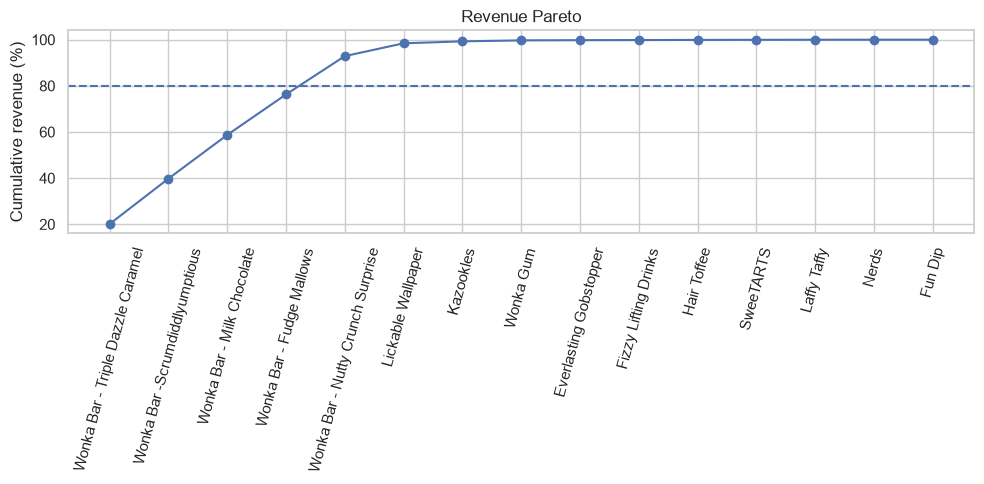

In [36]:
revenue_pareto = product_summary.sort_values("Sales", ascending=False).copy()
revenue_pareto["Cumulative Revenue %"] = revenue_pareto["Sales"].cumsum() / revenue_pareto["Sales"].sum() * 100

profit_pareto = product_summary.sort_values("Gross_Profit", ascending=False).copy()
profit_pareto["Cumulative Profit %"] = profit_pareto["Gross_Profit"].cumsum() / profit_pareto["Gross_Profit"].sum() * 100

print("Products to reach 80% of revenue:", (revenue_pareto["Cumulative Revenue %"] < 80).sum() + 1)
print("Products to reach 80% of profit:", (profit_pareto["Cumulative Profit %"] < 80).sum() + 1)

display(revenue_pareto[["Product Name", "Sales", "Cumulative Revenue %"]])

plt.figure(figsize=(10, 5))
plt.plot(revenue_pareto["Product Name"], revenue_pareto["Cumulative Revenue %"], marker="o")
plt.axhline(80, linestyle="--")
plt.xticks(rotation=75)
plt.ylabel("Cumulative revenue (%)")
plt.title("Revenue Pareto")
plt.tight_layout()
save_figure("revenue_pareto.png")
plt.show()

## 13. Cost and low margin products

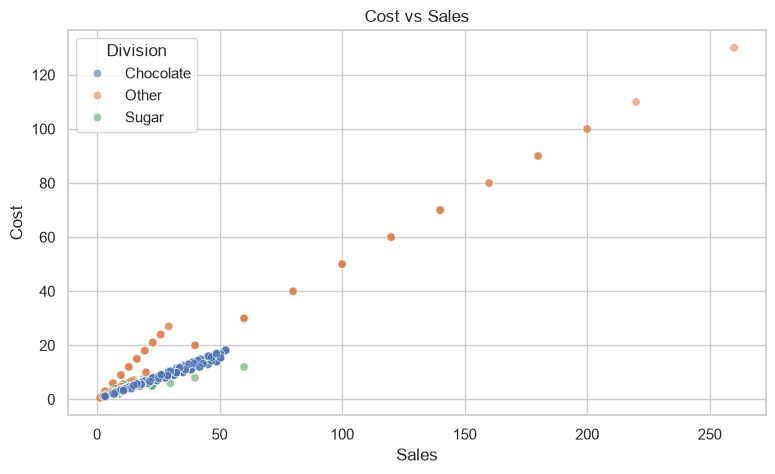

,Product Name,Sales,Cost,Gross_Profit,Gross Margin
4,Kazookles,1205.75,1113.0,92.75,7.692308
2,Fun Dip,12.00,7.2,4.80,40.000000
7,Nerds,15.00,8.0,7.00,46.666667
8,SweeTARTS,61.50,32.8,28.70,46.666667
6,Lickable Wallpaper,7860.00,3930.0,3930.00,50.000000


In [37]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data, x="Sales", y="Cost", hue="Division", alpha=0.6)
plt.title("Cost vs Sales")
save_figure("cost_vs_sales.png")
plt.show()

low_margin_products = product_summary.sort_values("Gross Margin")
display(low_margin_products[["Product Name", "Sales", "Cost", "Gross_Profit", "Gross Margin"]].head(5))

## 14. Region and shipping mode

,Region,Sales,Gross_Profit,Gross Margin,Share of Sales
0,Atlantic,41197.24,26973.70,65.474532,29.056415
1,Gulf,22247.26,14700.67,66.078564,15.690993
2,Interior,32037.60,21282.49,66.429726,22.596121
3,Pacific,46301.53,30485.94,65.842187,32.656471


,Ship Mode,Sales,Gross_Profit,Gross Margin,Share of Sales
0,First Class,21319.39,14011.09,65.719939,15.036567
1,Same Day,7113.67,4700.73,66.080237,5.017272
2,Second Class,27860.22,18306.52,65.708455,19.649814
3,Standard Class,85490.35,56424.46,66.000970,60.296347


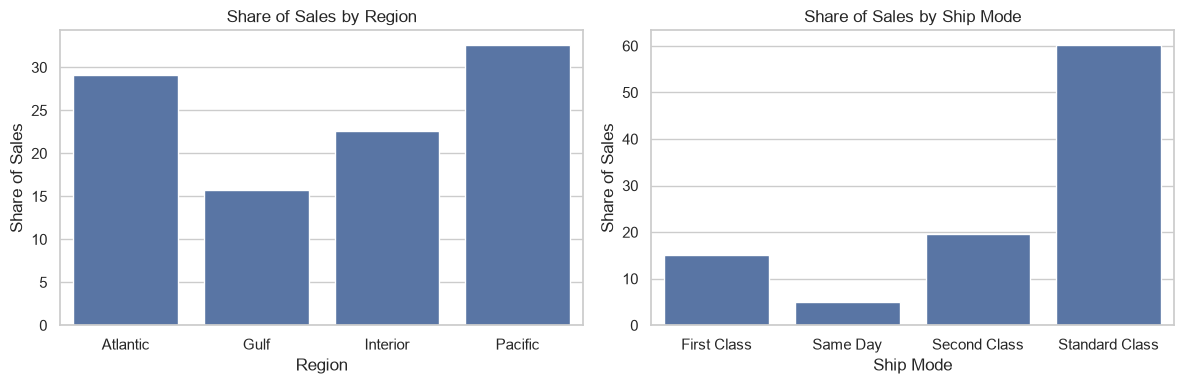

Region margin range: 65.47 to 66.43
Ship mode margin range: 65.71 to 66.08


In [38]:
region_summary = data.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()
region_summary["Gross Margin"] = region_summary["Gross_Profit"] / region_summary["Sales"] * 100
region_summary["Share of Sales"] = region_summary["Sales"] / region_summary["Sales"].sum() * 100

ship_summary = data.groupby("Ship Mode").agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()
ship_summary["Gross Margin"] = ship_summary["Gross_Profit"] / ship_summary["Sales"] * 100
ship_summary["Share of Sales"] = ship_summary["Sales"] / ship_summary["Sales"].sum() * 100

display(region_summary)
display(ship_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=region_summary, x="Region", y="Share of Sales", ax=axes[0])
axes[0].set_title("Share of Sales by Region")
sns.barplot(data=ship_summary, x="Ship Mode", y="Share of Sales", ax=axes[1])
axes[1].set_title("Share of Sales by Ship Mode")
plt.tight_layout()
save_figure("region_shipmode_sales.png")
plt.show()

# The margins are almost the same everywhere, so place and ship mode do not change margin.
print("Region margin range:", round(region_summary["Gross Margin"].min(), 2), "to", round(region_summary["Gross Margin"].max(), 2))
print("Ship mode margin range:", round(ship_summary["Gross Margin"].min(), 2), "to", round(ship_summary["Gross Margin"].max(), 2))

## 15. Monthly trend and seasonality

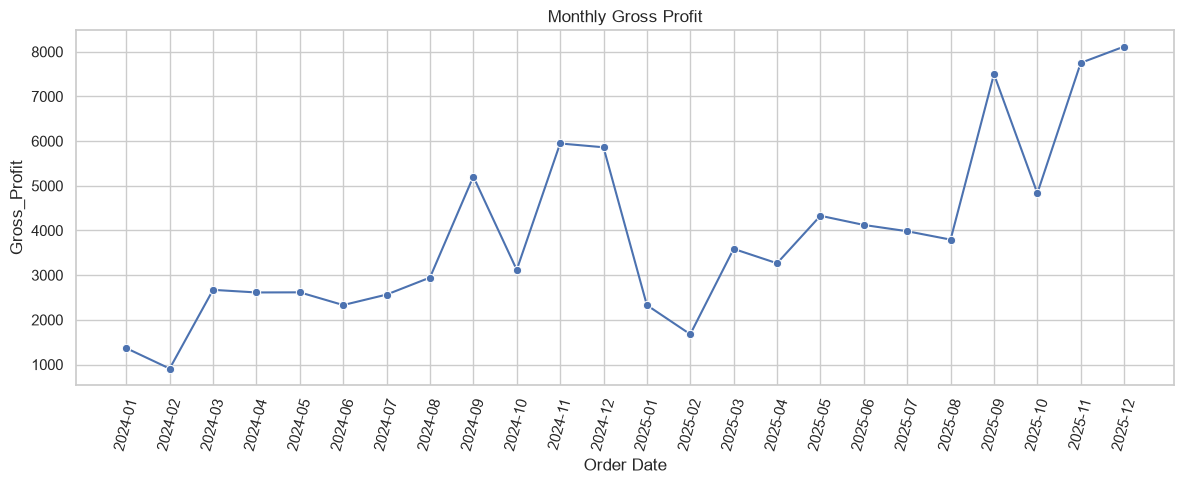

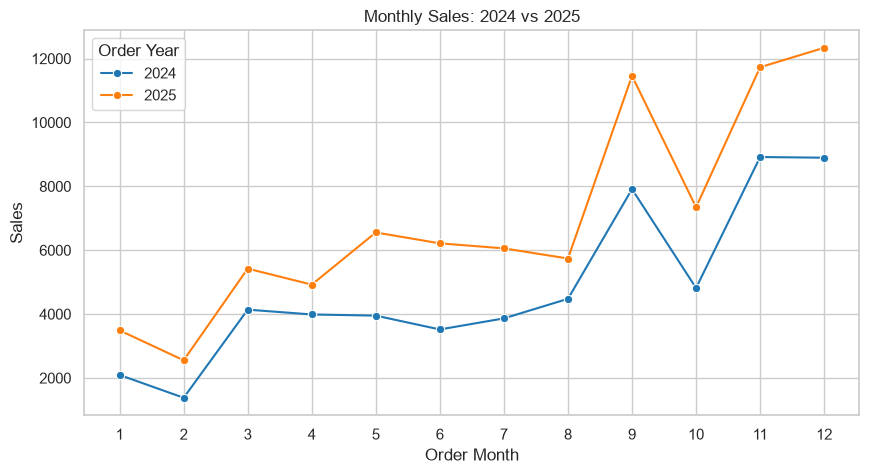

,Sales,Gross_Profit,Growth %
Order Year,,,
2024,57956.20,38151.43,NaN
2025,83827.43,55291.37,44.639279


Share of sales from September to December: 51.8%


In [39]:
monthly = data.groupby(data["Order Date"].dt.to_period("M")).agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()
monthly["Order Date"] = monthly["Order Date"].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="Order Date", y="Gross_Profit", marker="o")
plt.xticks(rotation=75)
plt.title("Monthly Gross Profit")
plt.tight_layout()
save_figure("monthly_gross_profit.png")
plt.show()

# Compare the two years month by month
year_sales = data.groupby(["Order Year", "Order Month"])["Sales"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=year_sales, x="Order Month", y="Sales", hue="Order Year", marker="o", palette="tab10")
plt.xticks(range(1, 13))
plt.title("Monthly Sales: 2024 vs 2025")
save_figure("monthly_sales_by_year.png")
plt.show()

# Yearly totals
year_total = data.groupby("Order Year").agg(Sales=("Sales", "sum"), Gross_Profit=("Gross Profit", "sum"))
year_total["Growth %"] = year_total["Sales"].pct_change() * 100
display(year_total)

# Share of sales from September to December
peak_share = data[data["Order Month"] >= 9]["Sales"].sum() / data["Sales"].sum() * 100
print(f"Share of sales from September to December: {peak_share:.1f}%")

## 16. Machine learning

A model that predicts gross margin is not useful here, because each product has one fixed margin.
Part A shows this. Part B builds a model that is useful: it forecasts monthly sales.

### Part A. Margin is just a product lookup

In [40]:
# Split by time: first 80% of rows for training, last 20% for testing
sorted_data = data.sort_values("Order Date")
split = int(len(sorted_data) * 0.8)
train = sorted_data.iloc[:split]
test = sorted_data.iloc[split:]

# Lookup table: average margin of each product in the training data
margin_lookup = train.groupby("Product Name")["Gross Margin"].mean()
lookup_predictions = test["Product Name"].map(margin_lookup)

# Baseline: always guess the middle margin
baseline_margin = train["Gross Margin"].median()

lookup_mae = mean_absolute_error(test["Gross Margin"], lookup_predictions)
baseline_mae = mean_absolute_error(test["Gross Margin"], [baseline_margin] * len(test))

print(f"Guess the median margin: error {baseline_mae:.2f} points")
print(f"Look up the product margin: error {lookup_mae:.4f} points")
print("A simple table is already perfect, so a margin model adds nothing.")

margin_lookup.round(2).to_csv(PROCESSED / "product_margin_lookup.csv")

Guess the median margin: error 2.90 points
Look up the product margin: error 0.0000 points
A simple table is already perfect, so a margin model adds nothing.


### Part B. Forecast monthly sales

In [41]:
monthly_sales = data.groupby(data["Order Date"].dt.to_period("M"))["Sales"].sum().reset_index()
monthly_sales["Month Number"] = range(1, len(monthly_sales) + 1)
monthly_sales["Month"] = monthly_sales["Order Date"].dt.month

X = monthly_sales[["Month Number", "Month"]]
y = monthly_sales["Sales"]

# First 18 months to train, last 6 months to test
X_train, X_test = X.iloc[:18], X.iloc[18:]
y_train, y_test = y.iloc[:18], y.iloc[18:]

print("Training months:", len(X_train))
print("Testing months:", len(X_test))

Training months: 18
Testing months: 6


### Train and evaluate

In [42]:
# Month Number captures the growth trend. Month (1 to 12) captures the season.
def make_model():
    prepare = ColumnTransformer(
        [("month", OneHotEncoder(handle_unknown="ignore"), ["Month"])],
        remainder="passthrough"
    )
    return make_pipeline(prepare, LinearRegression())


model = make_model()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_mae = mean_absolute_error(y_test, baseline.predict(X_test))

print(f"Model average error: {mae:,.0f}")
print(f"Model R2: {r2:.3f}")
print(f"Baseline average error (always the mean): {baseline_mae:,.0f}")

Model average error: 1,089
Model R2: 0.807
Baseline average error (always the mean): 4,272


### Check predictions

,Month,Actual Sales,Predicted Sales
0,2025-07,6057.67,5547.0
1,2025-08,5740.10,6159.0
2,2025-09,11457.60,9593.0
3,2025-10,7345.89,6497.0
4,2025-11,11728.86,10599.0
5,2025-12,12338.27,10578.0


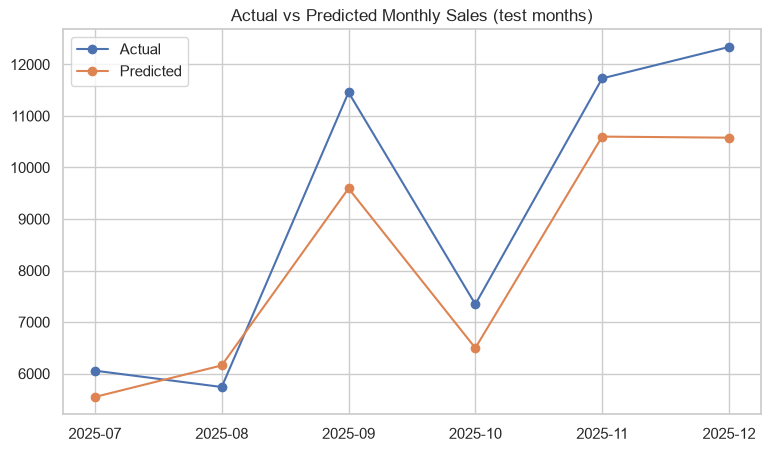

In [43]:
results = pd.DataFrame({
    "Month": monthly_sales["Order Date"].astype(str).iloc[18:].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": predictions.round(0)
})
display(results)

plt.figure(figsize=(9, 5))
plt.plot(results["Month"], results["Actual Sales"], marker="o", label="Actual")
plt.plot(results["Month"], results["Predicted Sales"], marker="o", label="Predicted")
plt.legend()
plt.title("Actual vs Predicted Monthly Sales (test months)")
save_figure("forecast_test.png")
plt.show()

### Train the final model and forecast the next 3 months

In [44]:
# The final model learns from all 24 months
final_model = make_model()
final_model.fit(X, y)

last_number = int(monthly_sales["Month Number"].max())
last_month = monthly_sales["Order Date"].iloc[-1]

future_months = pd.period_range(last_month + 1, periods=3, freq="M")
future = pd.DataFrame({
    "Month Number": [last_number + 1, last_number + 2, last_number + 3],
    "Month": future_months.month
})
future["Forecast Sales"] = final_model.predict(future).round(0)
future["Label"] = future_months.astype(str)
display(future)

print("Forecasts rest on only two years of data, so use them as a rough guide.")

,Month Number,Month,Forecast Sales,Label
0,25,1,6025.0,2026-01
1,26,2,5201.0,2026-02
2,27,3,8015.0,2026-03


Forecasts rest on only two years of data, so use them as a rough guide.


## 17. Save model

In [45]:
joblib.dump(final_model, MODELS / "sales_forecast_model.joblib")

metrics = {
    "Target": "Monthly Sales",
    "MAE": float(mae),
    "R2": float(r2),
    "Baseline_MAE": float(baseline_mae),
    "Months_Used_For_Final_Model": int(len(monthly_sales)),
    "Last_Month": str(last_month)
}

with open(MODELS / "model_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

print("Model and metrics saved in the models folder.")

Model and metrics saved in the models folder.


## 18. Load model and test

In [24]:
saved_model = joblib.load(MODELS / "sales_forecast_model.joblib")

sample = future[["Month Number", "Month"]].iloc[[0]]
print("Input:")
display(sample)
print("Forecast sales:", round(saved_model.predict(sample)[0]))

Input:


,Month Number,Month
0,25,1


Forecast sales: 6025
